# Задача 3

In [ ]:
format ELF64

public _start

include '../MyLibrary.asm'

section '.data' writeable
    result dq 0
    n db 0
    buf db 16

section '.text' executable

_start:
    mov rax, 0
    mov rdi, 0
    mov rsi, buf
    mov rdx, 16
    syscall

    mov byte [buf + rax - 1], 0

    mov rax, buf
    call ATOI
    mov [n], cl

    xor rcx, rcx
    mov cl, 1
    mov r8, 0
    .loop:
        xor rax, rax
        mov al, cl
        call calculate_addend

        ;знак при сложении
        cmp r8, 0 ; каждый чётный шаг цикла добавляем, каждый нечётный - вычитаем
        jg @f
        mov r8, 2
        neg rax
        @@:
        dec r8

        add [result], rax
        inc cl
        cmp cl, [n]
        jle .loop
    mov rax, [result]
    call print_int
    call exit

;input rax - k
;output rax - result
calculate_addend:
    push rdx
    push rsi

    mov rsi, rax
    inc rsi ;k+1

    mul rsi ;k*(k+1)
    dec rsi
    push rax

    ;(3k+1)
    mov rax, rsi
    mov rsi, 3
    mul rsi
    inc rax
    mov rsi, rax

    ;(3k+2)
    inc rax

    mul rsi
    pop rsi
    mul rsi

    pop rsi
    pop rdx

    ret


;input rax - intager
print_int:
    push rsi
    push rdi
    push rdx
    call ITOA

    mov rsi, rax
    mov rax, 1
    mov rdi, 1
    syscall

    pop rdx
    pop rdi
    pop rsi

    ret
;input: rax - pointer to the string
;output: rcx - integer
ATOI:
    push rsi ; pointer to end of string
    push rdx ; pointer to the string
    push rbx
    push R9
    push R8 ; хранит в себе не полный результат приобразования

    mov rsi, rax ; rsi должен указывать на конец строки
    mov rbx, rax
    xor R8, R8
    mov R9, 10 ; основание СС

    mov rax, 1 ; здесь хранятся степени 10

    @@: ; двигаем rsi до тех пор пока не встретим символ конца строки
        cmp byte [rsi], 0
        je @f
        inc rsi
        jmp @b
    @@:

    dec rsi
    @@:
    xor rcx, rcx
        mov cl, [rsi] ; Получаем ASCII код цифры
        sub rcx, '0' ; из ASCII получаем само значение цифры
        push rax
        mul rcx ; умножаем степень 10 на цифру

        add R8, rax; складываем результат умножения с предварительным результатом
        pop rax
        mul R9 ; увеличиваем степень 10

        cmp rsi,rbx ; проверяем не закончилось ли число
        je @f
        dec rsi
        jmp @b
    @@:

    mov rcx,R8

    pop R8
    pop R9
    pop rbx
    pop rdx
    pop rsi
    ret


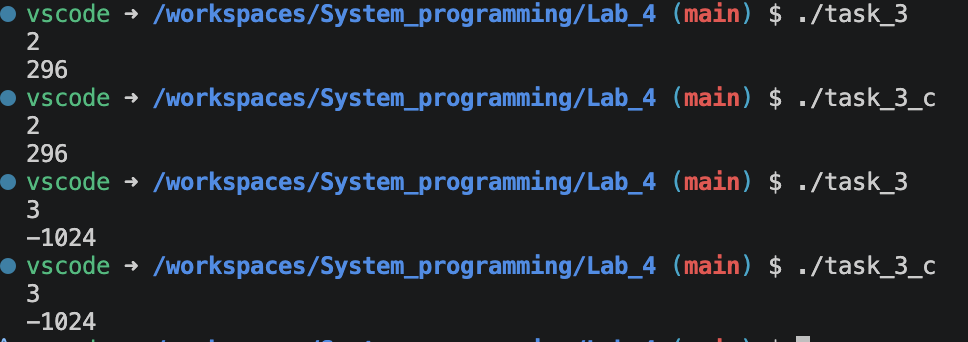

# Задача 11

In [ ]:
format ELF64

public _start

include '../MyLibrary.asm'

section '.bss' writeable
    n db 0

section '.text' executable

_start:
    mov rsi, buffer
    call input_keyboard

    mov rax, rsi
    call ATOI

    mov [n], cl
    xor r9, r9
    xor r8, r8

    .loop:
        call input_keyboard
        mov rax, rsi
        call ATOI

        cmp rcx, 0
        jg .true
            dec r8
            jmp .end_if

        .true:
            inc r8
        .end_if:

        inc r9b
        cmp r9b, [n]
        jl .loop

    cmp r8, 0
    jge .yes

    mov rax, 0
    call print_int
    call exit

    .yes:
        mov rax, 1
        call print_int
        call exit

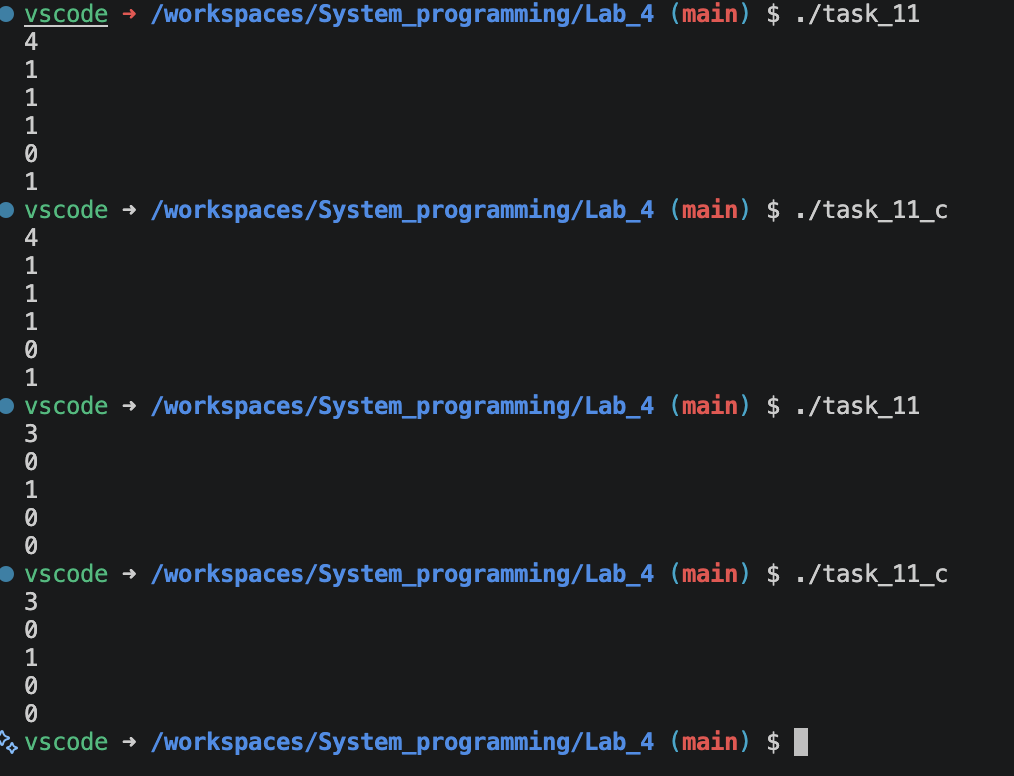

# Задача 12

In [ ]:
format ELF64

public _start

include '../MyLibrary.asm'

section '.text' executable

_start:
    mov rsi, buffer
    call input_keyboard

    xor rax, rax
    mov al, '0'
    .loop:
        cmp byte [rsi], '0'
        jl .true
        cmp al, byte [rsi]
        jg .false

        mov al, [rsi]
        inc rsi

        jmp .loop

    .false:
        mov rax, 0
        call print_int
        call exit
    .true:
        mov rax, 1
        call print_int
        call exit

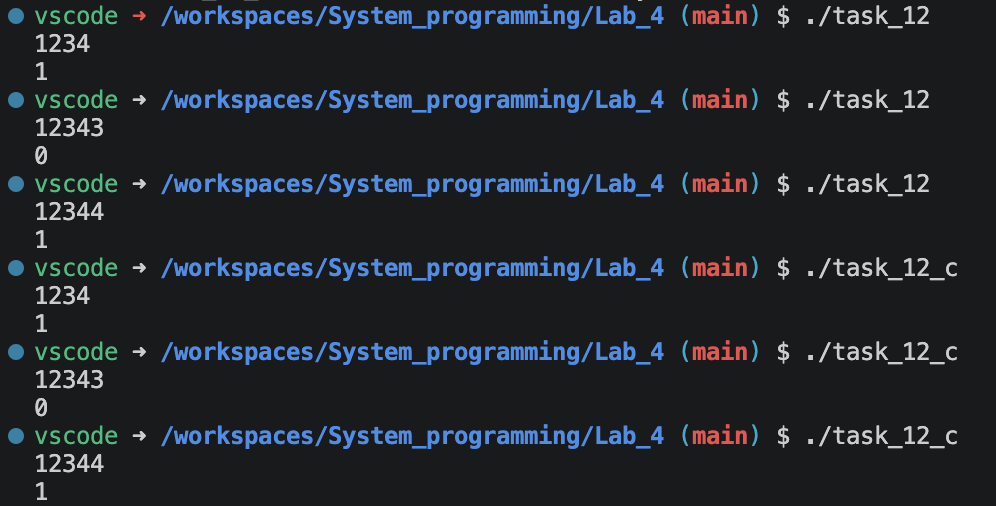